In [1]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install pylatexenc

Note: you may need to restart the kernel to use updated packages.


# The Two Guardians Riddle with Qiskit "The Easy Way" - BY SHUBHAM UNIYAL

## Introduction

The famous **"Two Guardians"** riddle is a classical logic puzzle.

1. You arrive at two doors, each guarded by a guardian.
2. One door hides a treasure.
3. One guardian always tells the truth.
4. The other guardian always lies.
5. Both guardians know where the treasure is.

You may ask **only one question** to **one guardian**. Your task is to find the correct door hiding the treasure!
%pip install qiskit qiskit-aer
Pause and think about your answer before revealing the solution.

<details>
<summary><strong>Click here to reveal the answer</strong></summary>

### ✅ Answer

Ask either guardian:

> **"Which door would the other guardian tell me not to open?"**

Both guardians will indicate the same door. You should **open that door**, as it leads to the treasure.

</details>

In [3]:
from qiskit import QuantumCircuit    # imports the QuantumCircuit class from the Qiskit library into our Python program
qc = QuantumCircuit(3,3)               # making a quantum circuit as qc with three qubits

## Representing the Puzzle

There are two unknowns.

1. Which door contains the treasure?
2. Which guardian is lying?

These two unknown variables naturally correspond to quantum bits.

We introduce three qubits. Why? 

let's say qubits q0, q1, q2 represents following : 

q0 - Treasure's Location, 

q1 - Answer of Guardians,

q2 - Which guardian lies

where,

(for convention) lets say For q2 : if the final output after measurement is :

q2 = 0 → Guardian 0 is lying (Guardian 1 tells the truth)

q2 = 1 → Guardian 1 is lying (Guardian 0 tells the truth)

we'll code this covention later!

In [4]:
# Step 1 : Creating the treasure position : with |000⟩
qc.h(0)       # We applied the Hadamard Gate on the first Qubit so that it's in the superposition which will mean that the treasure position can be at any door and we don't know it
              # The hadamard gate will transform first qubit |0⟩ into (|0⟩ + |1⟩)/√2.


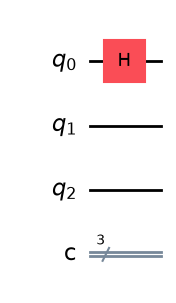

In [5]:
from copy import deepcopy

qc_step1 = qc.copy()

qc_step1.draw("mpl")  

In [6]:
# Step 2 : Making both the guardians know about the treasure location
# We can make both the guardians know the treasure location by entangling the qubit holding the treasure location(q0) and 
# the qubit which is responsible for guardian's answers (q1); as they can only answer if they know the location.
qc_step1.cx(0,1)   # Uptill this point, only q0 contained information about the treasure.
             # However, the puzzle states that both guardians know where the treasure is.
             # To model this, the information stored in q0 must also be available in q1.
             # This is achieved using a Controlled-NOT (CNOT) gate represented in qiskit by cx.


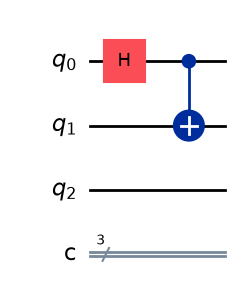

In [7]:
qc_step2 = qc_step1.copy()

qc_step2.draw("mpl")

### Step 2: Make Both Guardians Know the Treasure Location

Before applying the CNOT gate, the circuit has already applied a Hadamard gate to **q0**. Initially, all three qubits are in the state

$$
|000\rangle
$$

where:

- **q0 = 0** (treasure location)
- **q1 = 0** (Guardian's knowledge)
- **q2 = 0** (lying guardian indicator)

#### Applying the Hadamard Gate

The Hadamard gate is applied to **q0**:

A Hadamard gate transforms a single qubit from

$$
|0\rangle
$$

to

$$
\frac{|0\rangle + |1\rangle}{\sqrt{2}}.
$$

Since **q1** and **q2** remain unchanged in the $|0\rangle$ state, the complete three-qubit system becomes

$$
\left(\frac{|0\rangle + |1\rangle}{\sqrt{2}}\right)\otimes|0\rangle\otimes|0\rangle.
$$

Expanding the tensor product gives

$$
\frac{|0\rangle\otimes|0\rangle\otimes|0\rangle + |1\rangle\otimes|0\rangle\otimes|0\rangle}{\sqrt{2}}.
$$

Writing the tensor products as basis states gives

$$
\frac{|000\rangle + |100\rangle}{\sqrt{2}}.
$$

Therefore, the quantum state immediately **before** applying the CNOT gate is

$$
\boxed{\frac{|000\rangle + |100\rangle}{\sqrt{2}}.}
$$





#### Applying the CNOT Gate

A Controlled-NOT (CNOT) gate is applied with **q0** as the control qubit and **q1** as the target qubit.

The CNOT gate follows the rule:

- If the control qubit is **0**, the target qubit remains unchanged.
- If the control qubit is **1**, the target qubit is flipped.

The CNOT gate acts on each term of the superposition independently.

For the first term,

$$
|000\rangle,
$$

the control qubit is 0, so the state remains

$$
|000\rangle.
$$

For the second term

$$
|100\rangle,
$$

the control qubit is 1, so the target qubit **q1** flips from 0 to 1:

$$
|100\rangle \rightarrow |110\rangle.
$$

Therefore, after applying the CNOT gate, the quantum state becomes

$$
\boxed{\frac{|000\rangle + |110\rangle}{\sqrt{2}}.}
$$

This state is now **entangled**, meaning both guardians always possess the same information about the treasure's location. The treasure is simultaneously considered to be behind both possible doors until the qubits are measured.

**Notice that : At this point**

**q0 = Treasure location along with guardian's knowledge**

**q1 = Copy of treasure location along with guardian's knowledge**

**The circuit has not yet introduced truthfulness or deception.**

# Step 3: Randomly Choosing the Lying Guardian

At the end of **Step 2**, both **q0** and **q1** contain identical information about the treasure's location. The quantum state is

$$
\frac{|000\rangle + |110\rangle}{\sqrt{2}}.
$$

This state represents two possible treasure locations existing simultaneously:

- The treasure is behind the left door.
- The treasure is behind the right door.

Since both guardians know the treasure's location, both qubits contain the same information.

However, the puzzle introduces another uncertainty:

> **Which guardian is lying?**

Just like the treasure location, the identity of the liar is initially unknown. Since either guardian could be the liar, we again use quantum superposition to represent both possibilities simultaneously.

To do this, we use the third qubit, **q2**.

Initially,

$$
q_2 = |0\rangle.
$$

A Hadamard gate is applied to **q2**.

```

In [8]:
qc_step2.h(2)  # we applied Hadamard gate to the third qubit which will introduce the lying, since any of the guardian could be lying,
         # we represent it as superposition of the third qubit.

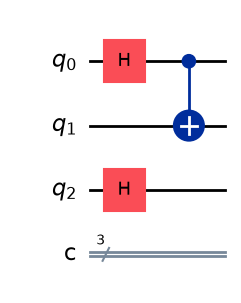

In [9]:
qc_step3 = qc_step2.copy()

qc_step3.draw("mpl")

**The Hadamard transforms**

$$
|0\rangle
$$

into

$$
\frac{|0\rangle + |1\rangle}{\sqrt{2}}.
$$

We define the following convention throughout this implementation:

- **q2 = 0** → Guardian 0 lies, Guardian 1 tells the truth.
- **q2 = 1** → Guardian 1 lies, Guardian 0 tells the truth.

This convention is arbitrary, but it must remain consistent throughout the circuit.

Before applying the Hadamard gate to **q2**, the quantum state is

$$
\frac{|000\rangle+|110\rangle}{\sqrt2}.
$$

Since q2 is still in the state $|0\rangle$, this state can also be written as

$$
\left(
\frac{|00\rangle+|11\rangle}{\sqrt2}
\right)\otimes|0\rangle.
$$

Applying a Hadamard gate to q2 transforms

$$
|0\rangle
\rightarrow
\frac{|0\rangle+|1\rangle}{\sqrt2}.
$$

Therefore, the complete system becomes

$$
\left(
\frac{|00\rangle+|11\rangle}{\sqrt2}
\right)
\otimes
\left(
\frac{|0\rangle+|1\rangle}{\sqrt2}
\right).
$$

Multiplying the amplitudes gives

$$
\frac{1}{2}
(|00\rangle+|11\rangle)
\otimes
(|0\rangle+|1\rangle).
$$

Expanding the tensor product,

$$
=
\frac{1}{2}
(
|00\rangle\otimes|0\rangle
+
|00\rangle\otimes|1\rangle
+
|11\rangle\otimes|0\rangle
+
|11\rangle\otimes|1\rangle
).
$$

Writing these tensor products as computational basis states,

$$
=
\frac{
|000\rangle
+
|001\rangle
+
|110\rangle
+
|111\rangle
}{2}.
$$

The quantum computer now represents four equally probable classical situations simultaneously.

Each basis state corresponds to a unique combination of:

- the treasure location (encoded by q0 and q1), and
- the value of q2, which determines which guardian will later be designated as the liar.

| Quantum State | Treasure Location | q2 Value | Meaning |
|---------------|-------------------|----------|---------|
| $|000\rangle$ | Left Door | 0 | Treasure is on the left, Guardian 0 will be the liar. |
| $|001\rangle$ | Left Door | 1 | Treasure is on the left, Guardian 1 will be the liar. |
| $|110\rangle$ | Right Door | 0 | Treasure is on the right, Guardian 0 will be the liar. |
| $|111\rangle$ | Right Door | 1 | Treasure is on the right, Guardian 1 will be the liar. |

Each basis state has an amplitude of

$$
\frac{1}{2},
$$

which means that each state has a probability of

$$
\left(\frac{1}{2}\right)^2
=
\frac{1}{4},
$$

or **25%**.

Unlike a classical computer, which would evaluate these four possibilities one at a time, the quantum computer carries all four possibilities simultaneously through the remainder of the computation.

At this stage, however, both q0 and q1 still contain the correct treasure location. 
No guardian has lied yet because the controlled operations that invert the guardian's answer to make it a lie, have not yet been applied. The value of q2 merely identifies which guardian will be lying in the next step.

# Step 4: Introducing the Lying Behaviour

The next objective is to modify the circuit so that **exactly one guardian gives an incorrect answer or rather we say 'lie'**.

Up to this point,

- q0 stores the treasure location,
- q1 stores an identical copy of the treasure location.

**After introducing the lying behaviour, these qubits will instead represent the answers that each guardian would actually give.**

**The treasure location itself never changes. Instead, the guardians' responses are conditionally modified.**


# Step 4A: Make Guardian 1 lie.
### q2 is the control qubit, and q1 is the target qubit.
### Our convention:
### q2 = 0 -> Guardian 0 lies, Guardian 1 tells the truth.
### q2 = 1 -> Guardian 1 lies, Guardian 0 tells the truth.
#
### A standard CNOT flips q1 only when q2 = 1.
### Therefore:
### - If q2 = 0, q1 remains unchanged because Guardian 1 is truthful.
### - If q2 = 1, q1 flips to represent Guardian 1's lie.
# Hence, The CNOT gate perfectly mimics the convention we're using here.


In [10]:
qc_step3.cx(2,1)  # we'll apply a CNOT gate making q2 control and q1(Guardian 1) target,
            # which means : Depending upon which guardian is lying, we'll actually make the qubit flip to represent a lie.
            # if q2=0, it'll mean guardian 0 is lying, that means guardian 1 is telling the truth. Computionally it'll also means that the
            # control qubit is 0, in that case no action is done on q1!(guardian 1 stays truthful) 
            # but if q2=1(guardian 1 is lying), computionally it'll mean that the control qubit is 1 
            # and hence it'll flip q1(target), making guardian 1's answer a lie.

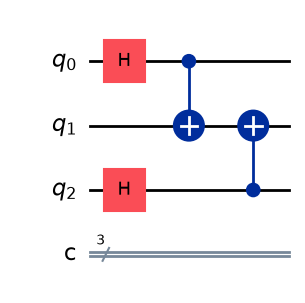

In [11]:
qc_step4 = qc_step3.copy()

qc_step4.draw("mpl")

## Making Guardian 1 Lie

The first controlled operation is

qc.cx(2,1)

In this gate,

- q2 is the **control qubit**.
- q1 is the **target qubit**.

The CNOT gate flips q1 whenever the control qubit q2 is equal to 1.

The gate acts on every basis state independently.

### First basis state

$$
|000\rangle
$$

Since

$$
q_2 = 0,
$$

the control is inactive, so nothing changes.

$$
|000\rangle
\rightarrow
|000\rangle.
$$

### Second basis state

$$
|001\rangle
$$

Here,

$$
q_2 = 1.
$$

The control is active, so q1 flips

$$
0 \rightarrow 1.
$$

Therefore,

$$
|001\rangle
\rightarrow
|011\rangle.
$$

### Third basis state

$$
|110\rangle
$$

Again,

$$
q_2 = 0,
$$

so the state remains

$$
|110\rangle.
$$

### Fourth basis state

$$
|111\rangle
$$

Since

$$
q_2 = 1,
$$

q1 flips

$$
1 \rightarrow 0.
$$

Therefore,

$$
|111\rangle
\rightarrow
|101\rangle.
$$

After applying the CNOT gate, the quantum state becomes

$$
\frac{
|000\rangle
+
|011\rangle
+
|110\rangle
+
|101\rangle
}{2}.
$$

The answer stored in q1 has now been inverted whenever q2 activates the CNOT gate.

# Making Guardian 0 Lie

### Let's explain how Guardian 0 lies in our 'The Treasure Door' quantum circuit.
### 1. The rule
### In our project, the value of q2 determines which guardian is lying:
### - q2 = 0: Guardian 0 is lying.
### - q2 = 1: Guardian 1 is lying.
### A standard CNOT flips its target only when its control is 1. But Guardian 0 must lie when q2 is 0, so we need to make the circuit respond to zero instead.

### This is achieved using the sequence

### qc.x(2)
### qc.cx(2,0)
### qc.x(2)

### The three gates work together as follows:

### 1. The first X gate flips q2.
### 2. The CNOT is now activated for the opposite value of q2.
### 3. The final X gate restores q2 to its original state.

### This effectively creates a controlled operation that activates when q2 is equal to 0 instead of 1.

### As with every quantum gate, these operations act simultaneously on every basis state in the superposition.

### After this sequence, the circuit satisfies the conditions of the original puzzle:

### - The treasure may be behind either door.
### - Either guardian may be the liar.
### - Exactly one guardian tells the truth.
### - Exactly one guardian lies.

In [12]:
# we have already put condition for when guardian 1 lies, now we make guardian 0 lie.
# Now, Guardian 0 would lie only if q2=0, but we cannot apply CNOT for control qubit having values=0, it has to be 1. therefore,
# we'll apply gates to make Guardian 0 lie when q2=0.
# Since a normal CNOT only flips the target when the control qubit is 1,
# we first apply an X gate to q2 to temporarily reverse its value.
# If q2=0, the X gate changes it to 1, allowing the CNOT to activate.
# The CNOT gate makes q2 the control and q0 (Guardian 0) the target.
# Therefore, when the original q2=0 (Guardian 0 is lying),
# the CNOT flips q0, making Guardian 0's answer a lie.
# But if q2=1 (Guardian 1 is lying), the X gate changes q2 to 0,
# so the CNOT does nothing to q0, meaning Guardian 0 stays truthful.
# Finally, we apply another X gate to q2 to restore its original value,
# so we still know which guardian was lying.

qc_step4.x(2)  
qc_step4.cx(2,0)      
qc_step4.x(2)

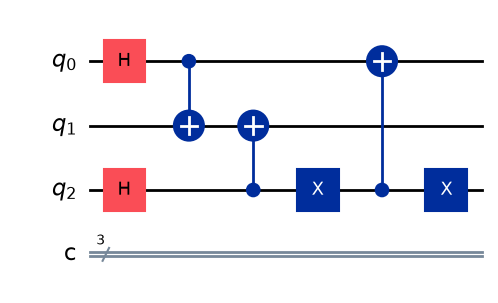

In [13]:
qc_step5 = qc_step4.copy()

qc_step5.draw("mpl")

## Interpretation After Step 4

The interpretation of q0 and q1 changes after the lying operations.

Before Step 4,

- q0 represented the treasure location.
- q1 represented a copy of the treasure location.

After Step 4, q0 and q1 encode the two guardians' answers. Initially, both qubits contain the treasure-location bit. The controlled operations flip q0 when Guardian 0 is designated as the liar and flip q1 when Guardian 1 is designated as the liar. Therefore, one guardian's answer is the opposite of the treasure location, while the other guardian's answer remains truthful. The circuit preserves the quantum superposition of the possible situations until measurement.

## Quantum State After Making Guardian 0 Lie

After making Guardian 1 lie, the quantum state was

$$
\frac{
|000\rangle
+
|011\rangle
+
|110\rangle
+
|101\rangle
}{2}.
$$

Now, we must also introduce the condition that **Guardian 0 lies whenever q2 = 0**.

To achieve this, we apply the following gates:

```python
qc_step4.x(2)
qc_step4.cx(2,0)
qc_step4.x(2)
```

Together, these gates flip q0 only when the original value of q2 is 0.

The operations act on each basis state independently.

---

### First Basis State

$$
|000\rangle
$$

Here,

- q0 = 0
- q1 = 0
- q2 = 0

Since q2 = 0, Guardian 0 is lying.

Therefore, q0 flips from 0 to 1.

$$
|000\rangle \rightarrow |100\rangle.
$$

---

### Second Basis State

$$
|011\rangle
$$

Here,

- q0 = 0
- q1 = 1
- q2 = 1

Since q2 = 1, Guardian 1 is lying and Guardian 0 is truthful.

Therefore, q0 remains unchanged.

$$
|011\rangle \rightarrow |011\rangle.
$$

---

### Third Basis State

$$
|110\rangle
$$

Here,

- q0 = 1
- q1 = 1
- q2 = 0

Since q2 = 0, Guardian 0 is lying.

Therefore, q0 flips from 1 to 0.

$$
|110\rangle \rightarrow |010\rangle.
$$

---

### Fourth Basis State

$$
|101\rangle
$$

Here,

- q0 = 1
- q1 = 0
- q2 = 1

Since q2 = 1, Guardian 1 is lying and Guardian 0 is truthful.

Therefore, q0 remains unchanged.

$$
|101\rangle \rightarrow |101\rangle.
$$

---

## Final Quantum State After Step 4

Combining all four transformed basis states gives

$$
\boxed{
\frac{
|100\rangle
+
|011\rangle
+
|010\rangle
+
|101\rangle
}{2}
}
$$

This is the quantum state after introducing the lying behaviour of both guardians.

Notice that:

- q0 represents Guardian 0's answer.
- q1 represents Guardian 1's answer.
- q2 determines which guardian is lying.

For every basis state, exactly one guardian gives the incorrect answer, while the other gives the truthful answer.

The amplitudes remain unchanged because the X and CNOT gates only flip computational basis bits.

The circuit remains in a superposition of all four possible situations.

## Step 5.1: Asking the Other Guardian (SWAP Gate)

The first part of the question is

> **"Which door would the other guardian..."**

To represent the phrase **"the other guardian"**, the answers stored in q0 and q1 must be exchanged.

This is achieved using a **SWAP gate**.

```python
qc_step5.swap(0,1)
```

The SWAP gate exchanges the quantum states of q0 and q1.

Mathematically,

$$
|ab\rangle
\longrightarrow
|ba\rangle,
$$

where

- \(a\) is the state of q0.
- \(b\) is the state of q1.

Unlike the CNOT gate, the SWAP gate always exchanges the two qubits regardless of their values.

The third qubit, q2, remains unchanged because it determines which guardian is lying.

**Note:** Throughout our mathematical explanation, basis states are written in the order $|q_0q_1q_2\rangle$.

---

### Quantum State Before the SWAP Gate

After introducing the lying behaviour of both guardians in Step 4, the quantum state is

$$
\frac{
|100\rangle
+
|011\rangle
+
|010\rangle
+
|101\rangle
}{2}.
$$

Recall that:

- q0 represents Guardian 0's answer.
- q1 represents Guardian 1's answer.
- q2 determines which guardian is lying.

The SWAP gate acts on each basis state independently.

---

### First Basis State

$$
|100\rangle
$$

Here,

- q0 = 1
- q1 = 0
- q2 = 0

Since q0 and q1 have different values, swapping them exchanges their positions.

Therefore,

$$
|100\rangle
\rightarrow
|010\rangle.
$$

Notice that q2 remains unchanged.

---

### Second Basis State

$$
|011\rangle
$$

Here,

- q0 = 0
- q1 = 1
- q2 = 1

The SWAP gate exchanges q0 and q1.

Therefore,

$$
|011\rangle
\rightarrow
|101\rangle.
$$

Again, q2 remains unchanged.

---

### Third Basis State

$$
|010\rangle
$$

Here,

- q0 = 0
- q1 = 1
- q2 = 0

After swapping q0 and q1,

$$
|010\rangle
\rightarrow
|100\rangle.
$$

The value of q2 remains unchanged.

---

### Fourth Basis State

$$
|101\rangle
$$

Here,

- q0 = 1
- q1 = 0
- q2 = 1

After exchanging q0 and q1,

$$
|101\rangle
\rightarrow
|011\rangle.
$$

The value of q2 remains unchanged.

---

### Quantum State After the SWAP Gate

Combining every transformed basis state gives

$$
\boxed{
\frac{
|010\rangle
+
|101\rangle
+
|100\rangle
+
|011\rangle
}{2}
}
$$

Notice that the amplitudes remain unchanged.

Only the positions of q0 and q1 have been exchanged in each basis state.

**An important observation:**

Although individual basis states have been transformed, the complete quantum state remains mathematically identical to the state before the SWAP gate.

This is because the same four basis states are present with equal amplitudes, only written in a different order.

Since addition is commutative,

$$
\frac{
|010\rangle
+
|101\rangle
+
|100\rangle
+
|011\rangle
}{2}
=
\frac{
|100\rangle
+
|011\rangle
+
|010\rangle
+
|101\rangle
}{2}.
$$

Therefore, the SWAP gate exchanges the guardian-answer registers, but this particular superposition is unchanged overall.

---

### Interpretation After the SWAP Gate

Before the SWAP,

- q0 represented Guardian 0's answer.
- q1 represented Guardian 1's answer.

After the SWAP,

- q0 now stores the answer previously held by Guardian 1.
- q1 now stores the answer previously held by Guardian 0.
- q2 still determines which guardian is lying.

The SWAP gate does not change which guardian is truthful or lying.

It simply exchanges the two answer registers.

In our simplified quantum model, this exchange represents the first part of referring to **"the other guardian."**

The next step will introduce the phrase

> **"...tell me not to open?"**

This requires inverting the guardian-answer qubits using Pauli-X gates.

---

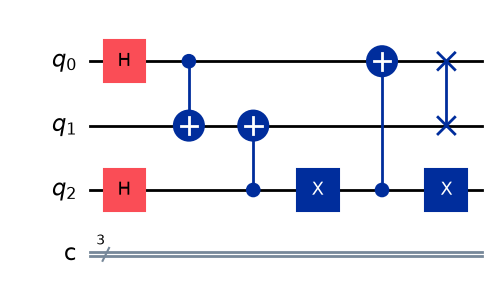

In [14]:
# Step 5.1: Asking the Other Guardian (SWAP Gate)

# Copy the completed Step 4 circuit
qc_step5 = qc_step4.copy()

# Exchange the answers stored in q0 and q1
qc_step5.swap(0, 1)

# Display the updated quantum circuit
qc_step5.draw("mpl")

## Step 5.2: Asking Which Door They Would Tell You **Not** to Open

The second part of the question is

> **"...tell me not to open?"**

The word **"not"** means the guardian's answer must be inverted.

To accomplish this, the circuit applies a Pauli-X gate to both guardian-answer qubits.

```python
qc_step5.x(0)
qc_step5.x(1)
```

The Pauli-X gate is the quantum equivalent of a classical NOT gate.

It performs

$$
|0\rangle
\rightarrow
|1\rangle,
$$

and

$$
|1\rangle
\rightarrow
|0\rangle.
$$

Therefore, applying an X gate to both q0 and q1 inverts their values independently.

The third qubit, q2, remains unchanged because it determines which guardian is lying.

**Note:** Throughout our mathematical explanation, basis states are written in the order $|q_0q_1q_2\rangle$.

---

### Quantum State Before the X Gates

After applying the SWAP gate in Step 5.1, the quantum state is

$$
\frac{
|010\rangle
+
|101\rangle
+
|100\rangle
+
|011\rangle
}{2}.
$$

Recall that after the SWAP gate:

- q0 stores the answer previously held by Guardian 1.
- q1 stores the answer previously held by Guardian 0.
- q2 determines which guardian is lying.

Now, the Pauli-X gates invert the answers stored in q0 and q1.

The X gates act on each basis state independently.

---

### First Basis State

$$
|010\rangle
$$

Here,

- q0 = 0
- q1 = 1
- q2 = 0

Applying the Pauli-X gates to q0 and q1:

$$
q_0: 0 \rightarrow 1
$$

$$
q_1: 1 \rightarrow 0
$$

Therefore, the first two qubits change as

$$
01 \rightarrow 10.
$$

The resulting basis state is

$$
|010\rangle
\rightarrow
|100\rangle.
$$

Notice that q2 remains unchanged.

---

### Second Basis State

$$
|101\rangle
$$

Here,

- q0 = 1
- q1 = 0
- q2 = 1

Applying the Pauli-X gates:

$$
q_0: 1 \rightarrow 0
$$

$$
q_1: 0 \rightarrow 1
$$

Therefore,

$$
10 \rightarrow 01.
$$

The resulting basis state is

$$
|101\rangle
\rightarrow
|011\rangle.
$$

Again, q2 remains unchanged.

---

### Third Basis State

$$
|100\rangle
$$

Here,

- q0 = 1
- q1 = 0
- q2 = 0

Applying the Pauli-X gates:

$$
q_0: 1 \rightarrow 0
$$

$$
q_1: 0 \rightarrow 1
$$

Therefore,

$$
10 \rightarrow 01.
$$

The resulting basis state is

$$
|100\rangle
\rightarrow
|010\rangle.
$$

The value of q2 remains unchanged.

---

### Fourth Basis State

$$
|011\rangle
$$

Here,

- q0 = 0
- q1 = 1
- q2 = 1

Applying the Pauli-X gates:

$$
q_0: 0 \rightarrow 1
$$

$$
q_1: 1 \rightarrow 0
$$

Therefore,

$$
01 \rightarrow 10.
$$

The resulting basis state is

$$
|011\rangle
\rightarrow
|101\rangle.
$$

The value of q2 remains unchanged.

---

### Quantum State After the X Gates

Combining every transformed basis state gives

$$
\boxed{
\frac{
|100\rangle
+
|011\rangle
+
|010\rangle
+
|101\rangle
}{2}
}
$$

Notice that the amplitudes remain unchanged.

The Pauli-X gates have inverted the values of q0 and q1 in every individual basis state.

However, an important observation is that the complete quantum state remains mathematically identical to the state before applying the X gates.

Before the X gates:

$$
\frac{
|010\rangle
+
|101\rangle
+
|100\rangle
+
|011\rangle
}{2}.
$$

After the X gates:

$$
\frac{
|100\rangle
+
|011\rangle
+
|010\rangle
+
|101\rangle
}{2}.
$$

Since addition is commutative, both expressions represent the same quantum state.

This happens because the four basis states have equal amplitudes, and the X gates simply exchange them with one another.

**Therefore, although each individual basis state is transformed, the overall superposition remains unchanged.**

---

### Interpretation After the X Gates

Before applying the Pauli-X gates, the answer registers represented the guardians' exchanged answers following the SWAP operation.

After applying the Pauli-X gates, both exchanged answers have been inverted.

The operations performed so far are:

1. **SWAP gate:** Exchanges the answers stored in q0 and q1 to represent the phrase "the other guardian."

2. **Pauli-X gates:** Invert both exchanged answers to represent the phrase "not to open."

3. **q2 remains unchanged:** The circuit still preserves the information about which guardian is lying.

In our simplified quantum model, these operations represent the first two parts of the question:

> **"Which door would the other guardian tell me not to open?"**

However, one important detail remains.

The guardian being questioned may also be the liar.

Therefore, the circuit must still account for that guardian's lying behaviour when answering the question about the other guardian.

This will be addressed in **Step 5.3: Applying the Lying Behaviour Again**.

---

In [15]:
qc_step5.x(0)
qc_step5.x(1)

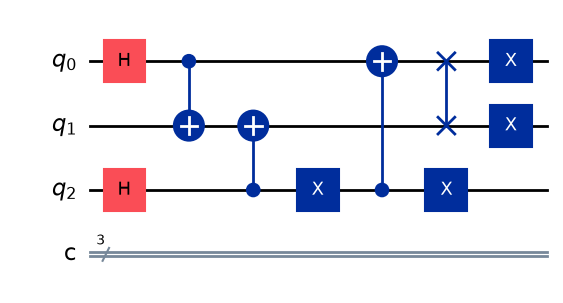

In [16]:
qc_step5_1 = qc_step5.copy()

qc_step5_1.draw("mpl")

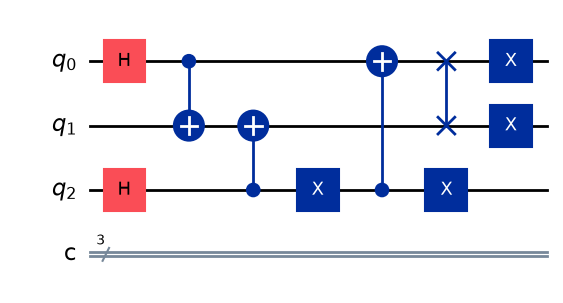

In [17]:
# Save the circuit after applying the Pauli-X gates
qc_step5_1 = qc_step5.copy()

# Display the updated quantum circuit
qc_step5_1.draw("mpl")

## Step 5.3: Applying the Lying Behaviour Again

After swapping the guardians' answers and inverting them to represent the phrase **"not to open"**, one important detail still remains.

The guardian being questioned may still be the liar.

For example, suppose Guardian 0 is the liar.

When asked,

> **"Which door would the other guardian tell me not to open?"**

Guardian 0 does not truthfully repeat Guardian 1's answer.

Instead, Guardian 0 lies **about** Guardian 1's answer.

Therefore, in our simplified quantum model, the circuit must once again apply the lying behaviour according to whichever guardian is designated as the liar.

Rather than designing a completely new circuit, the same controlled operations used earlier are applied once more.

```python
qc_step5_1.cx(2,1)

qc_step5_1.x(2)
qc_step5_1.cx(2,0)
qc_step5_1.x(2)
```

These gates conditionally invert the guardian-answer registers according to the value of q2.

Recall our convention:

- **q2 = 0:** Guardian 0 lies, Guardian 1 tells the truth.
- **q2 = 1:** Guardian 1 lies, Guardian 0 tells the truth.

The first CNOT gate flips q1 when q2 = 1.

The remaining X-CNOT-X sequence flips q0 when the original value of q2 = 0.

---

### Quantum State Before the Second Lying Circuit

After applying the SWAP gate and the two Pauli-X gates in Steps 5.1 and 5.2, the quantum state is

$$
\frac{
|100\rangle
+
|011\rangle
+
|010\rangle
+
|101\rangle
}{2}.
$$

Remember that our mathematical notation follows the order

$$
|q_0q_1q_2\rangle.
$$

The controlled operations now act on each basis state independently.

---

## First Controlled-NOT Gate

The first operation is

```python
qc_step5_1.cx(2,1)
```

where

- q2 is the control qubit.
- q1 is the target qubit.

The target qubit is flipped only when

$$
q_2=1.
$$

Applying this rule to every basis state:

### First Basis State

$$
|100\rangle
$$

Here,

- q0 = 1
- q1 = 0
- q2 = 0

Since

$$
q_2=0,
$$

the control is inactive.

Therefore, nothing changes.

$$
|100\rangle
\rightarrow
|100\rangle.
$$

---

### Second Basis State

$$
|011\rangle
$$

Here,

- q0 = 0
- q1 = 1
- q2 = 1

Since

$$
q_2=1,
$$

the CNOT gate activates and flips q1.

$$
q_1: 1\rightarrow0.
$$

Therefore,

$$
|011\rangle
\rightarrow
|001\rangle.
$$

---

### Third Basis State

$$
|010\rangle
$$

Here,

- q0 = 0
- q1 = 1
- q2 = 0

Since

$$
q_2=0,
$$

the control is inactive.

Therefore,

$$
|010\rangle
\rightarrow
|010\rangle.
$$

---

### Fourth Basis State

$$
|101\rangle
$$

Here,

- q0 = 1
- q1 = 0
- q2 = 1

Since

$$
q_2=1,
$$

the CNOT gate activates and flips q1.

$$
q_1: 0\rightarrow1.
$$

Therefore,

$$
|101\rangle
\rightarrow
|111\rangle.
$$

---

### Quantum State After the First CNOT Gate

Combining all four transformed basis states gives

$$
\boxed{
\frac{
|100\rangle
+
|001\rangle
+
|010\rangle
+
|111\rangle
}{2}
}
$$

The first CNOT gate has now inverted q1 whenever q2 = 1.

---

## Applying the X Gate to q2

Next, we apply

```python
qc_step5_1.x(2)
```

The Pauli-X gate flips

$$
|0\rangle
\leftrightarrow
|1\rangle.
$$

This operation temporarily reverses the value of q2.

Why?

Because the next CNOT gate must activate when the **original value of q2 is 0**, which represents Guardian 0 being the liar.

A standard CNOT activates only when its control is 1.

Therefore, we temporarily invert q2 so that the CNOT can activate for the opposite condition.

Applying the X gate to each basis state:

### First Basis State

$$
|100\rangle
\rightarrow
|101\rangle.
$$

### Second Basis State

$$
|001\rangle
\rightarrow
|000\rangle.
$$

### Third Basis State

$$
|010\rangle
\rightarrow
|011\rangle.
$$

### Fourth Basis State

$$
|111\rangle
\rightarrow
|110\rangle.
$$

---

### Quantum State After Inverting q2

The new quantum state is

$$
\boxed{
\frac{
|101\rangle
+
|000\rangle
+
|011\rangle
+
|110\rangle
}{2}
}
$$

Notice that only q2 has changed.

The values of q0 and q1 remain unchanged by this gate.

---

## Second Controlled-NOT Gate

The next operation is

```python
qc_step5_1.cx(2,0)
```

Now,

- q2 is the control qubit.
- q0 is the target qubit.

Whenever

$$
q_2=1,
$$

the CNOT gate flips q0.

Remember that q2 was temporarily inverted in the previous operation.

Therefore, this CNOT effectively activates for basis states where the **original value of q2 was 0**.

Applying the CNOT gate to each basis state:

### First Basis State

$$
|101\rangle
$$

Here,

$$
q_2=1.
$$

Therefore, q0 flips:

$$
q_0: 1\rightarrow0.
$$

The resulting state is

$$
|101\rangle
\rightarrow
|001\rangle.
$$

---

### Second Basis State

$$
|000\rangle
$$

Since

$$
q_2=0,
$$

the CNOT does not activate.

Therefore,

$$
|000\rangle
\rightarrow
|000\rangle.
$$

---

### Third Basis State

$$
|011\rangle
$$

Since

$$
q_2=1,
$$

q0 flips:

$$
q_0: 0\rightarrow1.
$$

Therefore,

$$
|011\rangle
\rightarrow
|111\rangle.
$$

---

### Fourth Basis State

$$
|110\rangle
$$

Since

$$
q_2=0,
$$

the CNOT does not activate.

Therefore,

$$
|110\rangle
\rightarrow
|110\rangle.
$$

---

### Quantum State After the Second CNOT Gate

Combining all four results gives

$$
\boxed{
\frac{
|001\rangle
+
|000\rangle
+
|111\rangle
+
|110\rangle
}{2}
}
$$

The second CNOT has now flipped q0 whenever the temporarily inverted value of q2 activates the control.

---

## Restoring q2

Finally, we apply

```python
qc_step5_1.x(2)
```

This second Pauli-X gate restores q2 to its original value.

Remember that q2 represents which guardian is lying.

We do not want to permanently change this information.

The first X gate was used only to temporarily invert the control condition.

Therefore, applying another X gate restores the original value.

Applying this operation to each basis state:

### First Basis State

$$
|001\rangle
\rightarrow
|000\rangle.
$$

### Second Basis State

$$
|000\rangle
\rightarrow
|001\rangle.
$$

### Third Basis State

$$
|111\rangle
\rightarrow
|110\rangle.
$$

### Fourth Basis State

$$
|110\rangle
\rightarrow
|111\rangle.
$$

---

## Final Quantum State After Step 5.3

Combining all four transformed basis states gives

$$
\boxed{
\frac{
|000\rangle
+
|001\rangle
+
|110\rangle
+
|111\rangle
}{2}
}
$$

This is the final quantum state before measurement.

Notice something important.

In every basis state, **q0 and q1 now have identical values**.

Let's examine the results:

| Quantum State | q0 | q1 | q2 |
|---|---|---|---|
| $|000\rangle$ | 0 | 0 | 0 |
| $|001\rangle$ | 0 | 0 | 1 |
| $|110\rangle$ | 1 | 1 | 0 |
| $|111\rangle$ | 1 | 1 | 1 |

Observe that:

- When q0 = 0, q1 = 0.
- When q0 = 1, q1 = 1.
- The value of q2 can be either 0 or 1.

Therefore, the two answer registers now agree regardless of which guardian was designated as the liar.

The controlled operations have restored the original treasure-location bit in both answer registers.

---

## Interpretation After Step 5.3

At this stage, the circuit has completed the planned logical transformations.

The operations performed in Step 5 are:

1. **SWAP gate:** Exchanges the guardian-answer registers to represent the phrase "the other guardian."

2. **Pauli-X gates:** Invert both exchanged answers to represent the phrase "not to open."

3. **Second lying circuit:** Applies the controlled inversions again according to which guardian is lying.

Together, these operations model the question

> **"Which door would the other guardian tell me not to open?"**

The important result is that the two answer registers now contain the same treasure-location bit in every possible case.

This can be verified directly from the final quantum state:

$$
\frac{
|000\rangle
+
|001\rangle
+
|110\rangle
+
|111\rangle
}{2}.
$$

Here,

- q0 and q1 encode identical answers.
- q2 still identifies which guardian is lying.
- All four possibilities remain in superposition.

The circuit has therefore restored the original treasure-location information in both answer registers.

**Important:** The final state still contains both possible treasure locations. Measurement will randomly select one of these possibilities, rather than reveal one predetermined treasure location.

In this simplified quantum model, the logical transformations preserve a consistent answer for each possible scenario.

Only one step remains: **Step 6 — Measuring the Quantum Circuit.**

---

In [18]:
# Step 5.3: Applying the Lying Behaviour Again

# Guardian 1 lies when q2 = 1
qc_step5_1.cx(2, 1)

# Guardian 0 lies when the original q2 = 0
qc_step5_1.x(2)
qc_step5_1.cx(2, 0)

# Restore q2 to its original value
qc_step5_1.x(2)

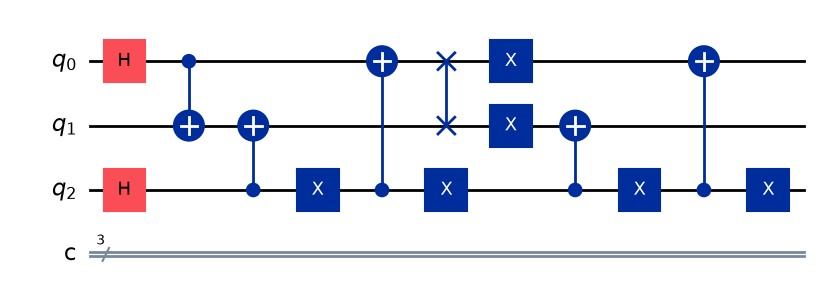

In [19]:
# Save the completed circuit before measurement
qc_step6 = qc_step5_1.copy()

# Display the updated quantum circuit
qc_step6.draw("mpl")

# Step 6: Measuring the Quantum Circuit

After all the quantum gates have been applied, the circuit has encoded the logical relationships needed to solve the Two Guardians riddle.

The final step is to **measure the qubits** so that their quantum states collapse into classical bits that can be interpreted.

In Qiskit, measurement is performed using the `measure()` method.

```python
qc_stepFinal.measure([0, 1, 2], [0, 1, 2])
```

This instruction measures each quantum qubit and stores the result in its corresponding classical bit.

- **q0 → c0**
- **q1 → c1**
- **q2 → c2**

After measurement, the quantum system produces one of the possible classical outcomes.

---

## Why Do We Measure?

Until this point, our quantum circuit has represented several possible situations in superposition.

These include:

- The treasure being behind either door.
- Guardian 0 or Guardian 1 being the liar.
- The answers corresponding to each possible situation.

However, we cannot directly read all the components of a quantum superposition as classical information.

Instead, measurement produces one outcome according to the probabilities determined by the quantum state.

This allows us to examine the answer produced during a particular execution of the circuit.

---

## Quantum State Before Measurement

At the end of Step 5.3, after applying the second lying circuit, the quantum state is

$$
\boxed{
|\psi\rangle =
\frac{
|000\rangle
+
|001\rangle
+
|110\rangle
+
|111\rangle
}{2}
}
$$

Remember that our mathematical notation follows the order

$$
|q_0q_1q_2\rangle.
$$

Here,

- **q0** represents the first final answer register.
- **q1** represents the second final answer register.
- **q2** determines which guardian is lying.

Notice that q0 and q1 have identical values in every basis state.

This is important because the circuit is designed to make the final answers agree regardless of which guardian was designated as the liar.

---

## Measurement Collapse

Before measurement, the quantum state is a superposition of four basis states.

In general, a quantum state can be written as

$$
|\psi\rangle = \sum_i c_i |i\rangle,
$$

where

- $|i\rangle$ represents a computational basis state.
- $c_i$ represents its probability amplitude.

When measurement is performed, one of these basis states is obtained.

The probability of measuring a particular state is calculated using the Born rule:

$$
P(i)=|c_i|^2.
$$

In our circuit, the amplitude of each basis state is

$$
c_i=\frac{1}{2}.
$$

Therefore,

$$
P(i)=\left|\frac{1}{2}\right|^2.
$$

$$
P(i)=\frac{1}{4}.
$$

Converting this to a percentage,

$$
\boxed{P(i)=25\%}
$$

Therefore, each of the four possible basis states has a 25% probability of being measured.

---

## Possible Measurement Outcomes

The final quantum state contains four possible outcomes.

Let's examine each one individually.

### First Possible Outcome

$$
|000\rangle
$$

Here,

- q0 = 0
- q1 = 0
- q2 = 0

Both answer registers indicate door 0.

Since q2 = 0, Guardian 0 was designated as the liar.

The probability of obtaining this outcome is

$$
P(000)=25\%.
$$

---

### Second Possible Outcome

$$
|001\rangle
$$

Here,

- q0 = 0
- q1 = 0
- q2 = 1

Both answer registers indicate door 0.

Since q2 = 1, Guardian 1 was designated as the liar.

The probability of obtaining this outcome is

$$
P(001)=25\%.
$$

---

### Third Possible Outcome

$$
|110\rangle
$$

Here,

- q0 = 1
- q1 = 1
- q2 = 0

Both answer registers indicate door 1.

Since q2 = 0, Guardian 0 was designated as the liar.

The probability of obtaining this outcome is

$$
P(110)=25\%.
$$

---

### Fourth Possible Outcome

$$
|111\rangle
$$

Here,

- q0 = 1
- q1 = 1
- q2 = 1

Both answer registers indicate door 1.

Since q2 = 1, Guardian 1 was designated as the liar.

The probability of obtaining this outcome is

$$
P(111)=25\%.
$$

---

## Important: Qiskit's Measurement Bit Ordering

Throughout our mathematical explanations, we have written quantum states in the order

$$
|q_0q_1q_2\rangle.
$$

However, Qiskit normally displays the measured classical bit strings in the reverse order:

$$
c_2c_1c_0.
$$

Therefore, our four theoretical states will appear in Qiskit's measurement results as follows:

| Mathematical State | Qiskit Output | Probability |
|---|---|---|
| $|000\rangle$ | `000` | 25% |
| $|001\rangle$ | `100` | 25% |
| $|110\rangle$ | `011` | 25% |
| $|111\rangle$ | `111` | 25% |

This is only a difference in how the bits are displayed.

It does not change the quantum state or the measurement probabilities.

For example, when Qiskit displays

```text
100
```

the classical bits mean

- c2 = 1
- c1 = 0
- c0 = 0

Therefore,

- q2 was measured as 1.
- q1 was measured as 0.
- q0 was measured as 0.

This corresponds to the mathematical state

$$
|001\rangle
$$

using our notebook's convention.

---

## Running the Circuit

Quantum measurements are probabilistic.

Therefore, a quantum circuit is usually executed multiple times.

Each execution is called a **shot**.

For example,

```python
from qiskit_aer import AerSimulator

simulator = AerSimulator()

result = simulator.run(qc_stepFinal, shots=1024).result()

counts = result.get_counts()
```

Here,

- `AerSimulator()` creates a simulator for executing the quantum circuit.
- `qc_stepFinal` is the completed circuit containing all gates and measurements.
- `shots=1024` means the circuit is executed 1024 times.
- `.result()` retrieves the simulation result.
- `.get_counts()` returns the frequency of each measured classical bit string.

**Important:** We must run `qc_stepFinal`, not the original `qc`, because `qc_stepFinal` contains the completed logical operations and measurements.

---

## Expected Measurement Results

Because each possible state has a probability of 25%, we expect approximately

$$
1024\times0.25=256
$$

occurrences of each valid outcome.

The possible Qiskit measurement bit strings are

```text
000
100
011
111
```

Each should appear approximately 256 times.

However, the exact counts may differ slightly between executions because measurement is probabilistic.

The probabilities remain

$$
P(000)=P(100)=P(011)=P(111)=\frac14.
$$

The probability of obtaining any other bit string is zero in the ideal circuit.

---

## Visualizing the Measurement Results

We can display the measurement frequencies using a histogram.

```python
from qiskit.visualization import plot_histogram

plot_histogram(counts)
```

The histogram displays:

- The possible measurement bit strings on the horizontal axis.
- The number of times each outcome appeared on the vertical axis.

Since all four valid outcomes have equal theoretical probabilities, the four bars should have approximately equal heights.

A slightly taller bar does not mean that outcome is the uniquely correct answer.

It simply means that particular result occurred more frequently in this simulation.

---

## Interpreting the Measurement Results

The most important relationship is between q0 and q1.

Let's examine the four possible outcomes again.

| Mathematical State | q0 | q1 | q2 |
|---|---|---|---|
| $|000\rangle$ | 0 | 0 | 0 |
| $|001\rangle$ | 0 | 0 | 1 |
| $|110\rangle$ | 1 | 1 | 0 |
| $|111\rangle$ | 1 | 1 | 1 |

Notice that

$$
q_0=q_1
$$

in every possible measurement outcome.

When q0 = 0,

$$
q_1=0.
$$

When q0 = 1,

$$
q_1=1.
$$

Therefore,

$$
\boxed{q_0=q_1}
$$

regardless of the value of q2.

This is the central property we wanted to demonstrate.

The two answer registers agree regardless of which guardian was designated as the liar.

---

## Interpreting q2

The third qubit still identifies which guardian was lying.

Recall our original convention:

- **q2 = 0:** Guardian 0 lies, Guardian 1 tells the truth.
- **q2 = 1:** Guardian 1 lies, Guardian 0 tells the truth.

The final circuit has preserved this information.

For example, consider the measurement

$$
|110\rangle.
$$

Here,

- q0 = 1
- q1 = 1
- q2 = 0

Both answer registers indicate door 1, while q2 tells us that Guardian 0 was the liar.

Now consider

$$
|111\rangle.
$$

Here,

- q0 = 1
- q1 = 1
- q2 = 1

Again, both answer registers indicate door 1, but this time Guardian 1 was the liar.

Therefore, the final answer can remain the same even when the identity of the liar changes.

This is exactly the logical independence we wanted to represent in our simplified quantum model.

---

## Why Multiple Outcomes Appear

The histogram does not contain only one bit string.

This is expected.

At the beginning of the circuit, we applied a Hadamard gate to the treasure-location qubit.

This placed the treasure location into a superposition of two possibilities.

We also applied a Hadamard gate to q2, representing the unknown identity of the lying guardian.

Consequently, the circuit represents four possible combinations.

Measurement randomly selects one combination during each shot.

The circuit does not begin with one predetermined treasure location that is unknown to us.

Instead, it begins with a superposition of possible treasure locations.

Therefore, different shots may indicate different doors.

**The important result is not that every measurement produces the same door.**

The important result is that, within each measurement outcome, the two answer registers agree, independently of which guardian is lying.

---

## Final Interpretation

The circuit has completed the following operations:

1. **Hadamard gate on q0:** Introduced uncertainty about the treasure location.

2. **CNOT between q0 and q1:** Correlated the answer register with the treasure location.

3. **Hadamard gate on q2:** Introduced uncertainty about which guardian is lying.

4. **Controlled lying operations:** Inverted the designated liar's answer.

5. **SWAP gate:** Exchanged the two guardian-answer registers.

6. **Pauli-X gates:** Inverted the exchanged answers to represent "not to open."

7. **Second lying circuit:** Applied the controlled lying operations again.

8. **Measurement:** Converted the final quantum state into classical measurement outcomes.

The final state before measurement was

$$
\boxed{
|\psi\rangle =
\frac{
|000\rangle
+
|001\rangle
+
|110\rangle
+
|111\rangle
}{2}
}
$$

The key observation is

$$
\boxed{q_0=q_1}
$$

for every possible outcome.

Thus, the circuit demonstrates that the two answer registers can encode the same treasure-location bit independently of the lying guardian's identity.

This reproduces an important logical property of the Two Guardians riddle within our simplified quantum model.

**Final Note:** This is a quantum representation of the puzzle's logical relationships, not a quantum method for discovering the location of a separately predetermined, hidden treasure. The circuit demonstrates how the final answer remains consistent with the treasure-location bit in each represented scenario.

---

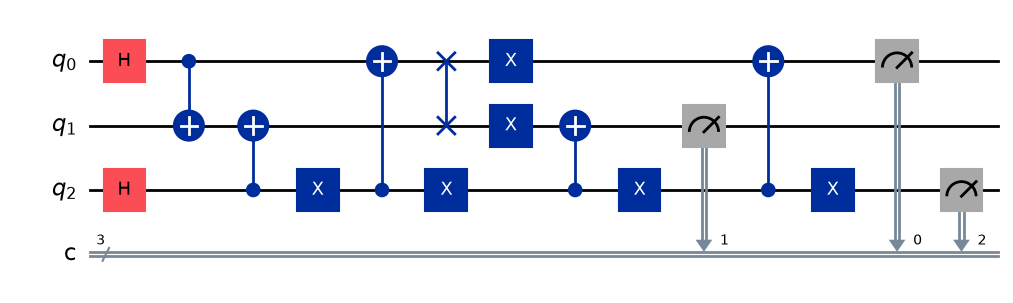

In [20]:
# Step 6: Measuring the Quantum Circuit

# Copy the completed circuit from Step 5.3
qc_stepFinal = qc_step6.copy()

# Measure all three qubits into their corresponding classical bits
qc_stepFinal.measure([0, 1, 2], [0, 1, 2])

# Display the completed circuit with measurement gates
qc_stepFinal.draw("mpl")

In [21]:
from qiskit_aer import AerSimulator

# Create the quantum circuit simulator
simulator = AerSimulator()

# Execute the completed circuit 1024 times
result = simulator.run(qc_stepFinal, shots=1024).result()

# Retrieve the measurement frequencies
counts = result.get_counts()

# Display the measurement results
print(counts)

{'100': 250, '000': 259, '011': 254, '111': 261}


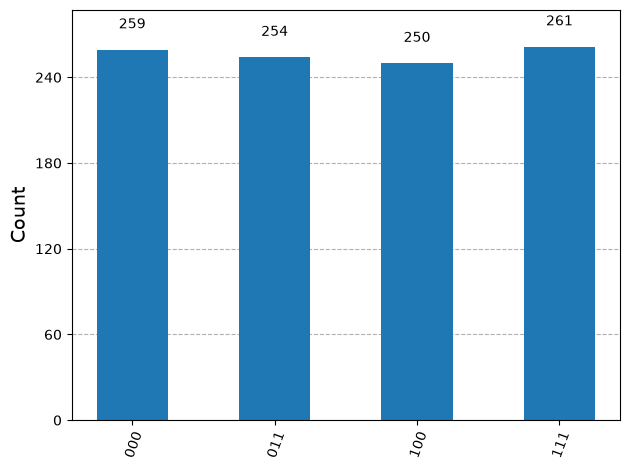

In [22]:
from qiskit.visualization import plot_histogram

# Visualize the frequencies of all measured outcomes
plot_histogram(counts)

In [23]:
# Interpret the measured bit strings using Qiskit's bit ordering

for outcome, frequency in sorted(counts.items()):

    # Qiskit displays classical bits in the order c2 c1 c0
    q2, q1, q0 = map(int, outcome)

    print(f"Measurement: {outcome}")
    print(f"Guardian answer registers: q0={q0}, q1={q1}")
    print(f"Lying guardian: Guardian {q2}")
    print(f"Indicated door: {q0}")
    print(f"Frequency: {frequency}")
    print("-----------------------------")

Measurement: 000
Guardian answer registers: q0=0, q1=0
Lying guardian: Guardian 0
Indicated door: 0
Frequency: 259
-----------------------------
Measurement: 011
Guardian answer registers: q0=1, q1=1
Lying guardian: Guardian 0
Indicated door: 1
Frequency: 254
-----------------------------
Measurement: 100
Guardian answer registers: q0=0, q1=0
Lying guardian: Guardian 1
Indicated door: 0
Frequency: 250
-----------------------------
Measurement: 111
Guardian answer registers: q0=1, q1=1
Lying guardian: Guardian 1
Indicated door: 1
Frequency: 261
-----------------------------
